In [36]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv(r"43_Dataset.csv")
df = df.sample(frac = 1, random_state = 1).reset_index(drop = True)

df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,202,0,3,"Sage, Mr. Frederick",male,NaN,8,2,CA. 2343,69.5500,NaN,S
1,116,0,3,"Pekoniemi, Mr. Edvard",male,21.0,0,0,STON/O 2. 3101294,7.9250,NaN,S
2,256,1,3,"Touma, Mrs. Darwis (Hanne Youssef Razi)",female,29.0,0,2,2650,15.2458,NaN,C
3,1104,0,2,"Deacon, Mr. Percy William",male,17.0,0,0,S.O.C. 14879,73.5000,NaN,S
4,196,1,1,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,B80,C
5,1282,0,1,"Payne, Mr. Vivian Ponsonby",male,23.0,0,0,12749,93.5000,B24,S
6,1139,0,2,"Drew, Mr. James Vivian",male,42.0,1,1,28220,32.5000,NaN,S
7,289,1,2,"Hosono, Mr. Masabumi",male,42.0,0,0,237798,13.0000,NaN,S
8,271,0,1,"Cairns, Mr. Alexander",male,NaN,0,0,113798,31.0000,NaN,S
9,249,1,1,"Beckwith, Mr. Richard Leonard",male,37.0,1,1,11751,52.5542,D35,S


# We will deal with Fare column.

`Step 1:` Take 100 sets with 50 Samples in each set.
`Step 2:` Take mean of each 100 sets. We'll have 100 means.
`Step 3:` Plot KDE or histogram of these 100 means. It'll be very near to the Normal Distribution.
`Step 4:` Verify the sample mean and sample standard deviation/variance with the population's.

**According to `central limit theorem`**
1) Sample mean = Population mean
2) Population Std.dev = s* root(n); where s = Sample std.dev and n = total_no_of samples in a set. Here n = 50

**Remember:** Drop missing values first as it will give error in some later opeeration.

In [85]:
df.dropna(inplace= True)
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [86]:
df['Fare'].sample(5).values.tolist()

[50.0, 78.85, 27.7208, 90.0, 13.0]

<Axes: ylabel='Density'>

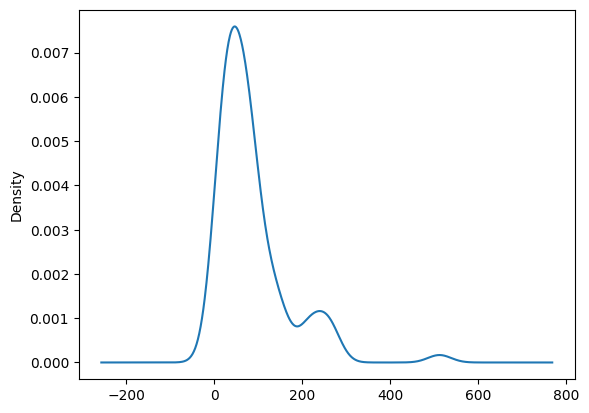

In [87]:
df['Fare'].plot(kind = "kde")

In [130]:
# Taking samples
sample_data = []

for i in range(10000):
    sample_fare = df['Fare'].sample(50, replace = True).values
    sample_data.append(sample_fare)

print(sample_data[0])
print(type(sample_data))

[113.275   13.      52.     151.55    27.7208 263.       7.65    55.9
 120.      32.3208 227.525  151.55    26.55    53.1     30.     120.
  26.55    27.7208 263.      93.5    106.425  262.375   69.3     39.
 221.7792 106.425   78.2667  13.7917  79.65    81.8583 262.375   27.7208
 113.275  106.425   52.5542  26.2875  30.5     39.4    263.       7.65
 211.3375  52.5542  93.5      0.      13.8625  56.9292  25.9292  57.75
 512.3292  56.9292]
<class 'list'>


In [131]:
# Converting sample_data to numpy array bcz np's array has mean() method
sample_data = np.array(sample_data)

print(sample_data[0])
print(type(sample_data))

[113.275   13.      52.     151.55    27.7208 263.       7.65    55.9
 120.      32.3208 227.525  151.55    26.55    53.1     30.     120.
  26.55    27.7208 263.      93.5    106.425  262.375   69.3     39.
 221.7792 106.425   78.2667  13.7917  79.65    81.8583 262.375   27.7208
 113.275  106.425   52.5542  26.2875  30.5     39.4    263.       7.65
 211.3375  52.5542  93.5      0.      13.8625  56.9292  25.9292  57.75
 512.3292  56.9292]
<class 'numpy.ndarray'>


In [132]:
sample_data[1]

array([ 25.7   ,  27.7208,  27.7208,  90.    ,  57.75  ,  93.5   ,
        61.175 ,  81.8583,  81.8583, 221.7792,  16.7   ,  66.6   ,
        35.5   ,  16.7   ,  61.175 ,  10.5   , 110.8833,  69.3   ,
        50.4958,  16.7   ,  52.    ,  76.2917,  26.2875,  79.2   ,
        34.6542, 262.375 ,  55.4417,  26.55  , 120.    ,   0.    ,
       134.5   ,  86.5   ,  77.9583,  79.65  ,  29.7   ,  93.5   ,
        10.4625,  83.475 ,  52.5542, 263.    ,  63.3583, 153.4625,
       211.3375,  26.55  , 211.3375, 247.5208,  83.1583,  39.    ,
        16.7   ,  89.1042])

In [133]:
# Taking means of each set
sample_means = sample_data.mean(axis = 1)    # 1 means we want mean of each row, i.e each nested array.

print(sample_means)
print()

print('Shape:', sample_means.shape)    # Should be 100

[98.501836 80.184914 93.479496 ... 89.320336 72.800916 93.44242 ]

Shape: (10000,)


<Axes: ylabel='Density'>

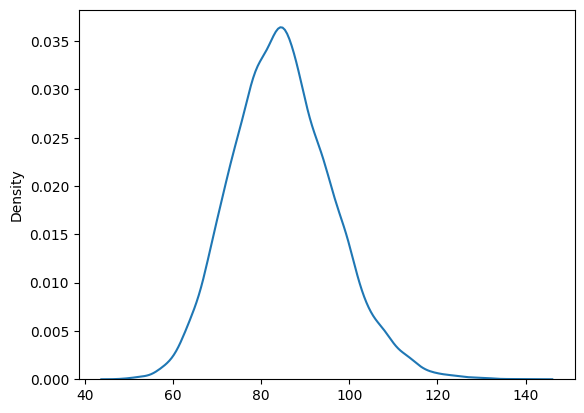

In [134]:
# Plotting mean

sns.kdeplot(sample_means)

# No matter what is the distribution of Fare column, distribution of sample means 
# will always ne near to normal distribution

# Formula of Standard Error
* Standard error = sample std_dev/ root(n)

In [ ]:
# Verify mean and std.dev of sample means and fare column

mean_sample = sample_means.mean()
mean_fare = df.Fare.mean()

print(f"""Fare mean: {mean_fare}
Sample mean: {mean_sample}""")

# See, means are almost same

# Claculate population std_dev from sample std
# Pop Std_dev = sample std_dev/ root(n); where n = sample size. Here it's 50

sample_std = sample_means.std(ddof = 1)
std_fare = df.Fare.std(ddof = 1)

calculated_population_std = sample_std/np.sqrt(50)

print(f"""Fare Std: {std_fare}
Calculated population std_dev: {calculated_population_std}""")

Fare mean: 84.94219259259259
Sample mean: 84.9639705628
Fare Std: 80.69865103201867
Calculated population std_dev: 1.6141342379504076


# Confidence Interval

- We know that `sample mean = population` mean. suppose `sample mean` is 50
- But instead of saying concluding `sample_mean = population_mean = 50`, we decide a range. Means we say, as sample mean is 50, population mean will be in the range of 50-53.
- This range is called `Confidence Interval`

# How to find `Confidence Interval`?

- See, the distribution of sample is Normal. So all the rules of normal distribution gets applied.
- Remember the rule, 
    - 68% of data lies between mean and 1 std_dev
    - 95% of data lies between mean and 2 std_dev
    - 99.7% of data lies between mean and 3 std_dev

- We consider 2 std_dev as it is experimented and decided by the statisticians.
- lower_limit of range = mean-2(std)
- upper_limit of range = mean+2(std)

In [94]:
df['Fare'].std()

80.69865103201867

In [138]:
sample_data.std(axis = 1).mean()

77.9933353393476

In [ ]:
lower_limit = sample_means.mean() - 2*(sample_means.std()/np.sqrt(50))
upper_limit = sample_means.mean() + 2*(sample_means.std()/np.sqrt(50))

print(lower_limit, upper_limit)

# This simply mean that there are 95% chance that population mean will fall between lower_limit and upper_limit

81.73586350435852 88.19207762124148


In [146]:
df['Fare'].mean()

84.94219259259259